In [2]:
# ============================================================
# CELL 1 — Imports
# ============================================================
import pandas as pd
import numpy as np
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, 
                             balanced_accuracy_score,
                             precision_score, recall_score)
from xgboost import XGBClassifier
import shap
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# ============================================================
# CELL 2 — Setup and load data
# ============================================================

# Paths
MASTER_PATH  = r"C:\Users\hp\StressDetection\master_features_restored.csv"
RESULTS_PATH = r"C:\Users\hp\StressDetection\ML\loso_results.csv"
SHAP_PATH    = r"C:\Users\hp\StressDetection\ML\shap_summary.png"
SHAP_BAR_PATH= r"C:\Users\hp\StressDetection\ML\shap_bar.png"

# Stream 1 — geometric features (gaze_mean included — restored CSV is clean)
GEO_FEATURES = [
    'EAR_mean', 'EAR_std', 'EAR_min', 'EAR_max', 'EAR_range',
    'blink_mean', 'blink_std', 'blink_min', 'blink_max', 'blink_range',
    'gaze_mean', 'gaze_std', 'gaze_min', 'gaze_max', 'gaze_range',
    'brow_mean', 'brow_std', 'brow_min', 'brow_max', 'brow_range',
    'lip_mean', 'lip_std', 'lip_min', 'lip_max', 'lip_range'
]

# Stream 2 — valence features
VAL_FEATURES = [
    'valence_mean', 'valence_std', 'valence_min', 'valence_max'
]

# Load data
df = pd.read_csv(MASTER_PATH)

print("Setup complete!")
print(f"Total rows:        {len(df)}")
print(f"Participants:      {df['participant'].nunique()}")
print(f"Tasks:             {df['task'].unique()}")
print(f"Label distribution:{df['label'].value_counts().to_dict()}")
print(f"Stream 1 features: {len(GEO_FEATURES)}")
print(f"Stream 2 features: {len(VAL_FEATURES)}")

Setup complete!
Total rows:        29736
Participants:      56
Tasks:             ['T1' 'T2' 'T3']
Label distribution:{1: 19824, 0: 9912}
Stream 1 features: 25
Stream 2 features: 4


In [4]:
# ============================================================
# CELL 3 — Late fusion LOSO function
# ============================================================
def run_loso_late_fusion(df, clf_name, clf_class, clf_params):
    """
    LOSO cross-validation with late fusion
    - Two separate classifiers — one per stream
    - Auto-weighted fusion per fold
    - Returns results per participant
    """
    participants = sorted(df['participant'].unique())
    fold_results = []

    for i, test_pid in enumerate(participants):
        print(f"  [{i+1:02d}/{len(participants)}] Test: {test_pid}", end='\r')

        train_df = df[df['participant'] != test_pid]
        test_df  = df[df['participant'] == test_pid]

        if test_df['label'].nunique() < 2:
            print(f"\n  WARNING: Participant {test_pid} has one class — skipping.")
            continue

        # Extract features and labels
        X_train_geo = train_df[GEO_FEATURES].values.astype(float)
        X_test_geo  = test_df[GEO_FEATURES].values.astype(float)
        X_train_val = train_df[VAL_FEATURES].values.astype(float)
        X_test_val  = test_df[VAL_FEATURES].values.astype(float)
        y_train     = train_df['label'].values
        y_test      = test_df['label'].values

        # Handle NaN — replace with training column mean
        for X_tr, X_te in [(X_train_geo, X_test_geo), 
                            (X_train_val, X_test_val)]:
            col_means = np.nanmean(X_tr, axis=0)
            for j in range(X_tr.shape[1]):
                X_tr[np.isnan(X_tr[:, j]), j] = col_means[j]
                X_te[np.isnan(X_te[:, j]), j] = col_means[j]

        # StandardScaler — fit on train only
        scaler_geo = StandardScaler()
        scaler_val = StandardScaler()
        X_train_geo = scaler_geo.fit_transform(X_train_geo)
        X_test_geo  = scaler_geo.transform(X_test_geo)
        X_train_val = scaler_val.fit_transform(X_train_val)
        X_test_val  = scaler_val.transform(X_test_val)

        # Train Stream 1 and Stream 2
        clf1 = clf_class(**clf_params)
        clf2 = clf_class(**clf_params)
        clf1.fit(X_train_geo, y_train)
        clf2.fit(X_train_val, y_train)

        # Fusion weights from training accuracy
        acc1 = accuracy_score(y_train, clf1.predict(X_train_geo))
        acc2 = accuracy_score(y_train, clf2.predict(X_train_val))
        w1   = acc1 / (acc1 + acc2)
        w2   = acc2 / (acc1 + acc2)

        # Probabilities on test participant
        p1      = clf1.predict_proba(X_test_geo)[:, 1]
        p2      = clf2.predict_proba(X_test_val)[:, 1]
        p_final = w1 * p1 + w2 * p2
        preds   = (p_final >= 0.5).astype(int)

        # Store fold results
        fold_results.append({
            'participant':  test_pid,
            'classifier':   clf_name,
            'accuracy':     accuracy_score(y_test, preds),
            'f1':           f1_score(y_test, preds, zero_division=0),
            'precision':    precision_score(y_test, preds, zero_division=0),
            'recall':       recall_score(y_test, preds, zero_division=0),
            'balanced_acc': balanced_accuracy_score(y_test, preds),
            'w1':           w1,
            'w2':           w2,
            'n_test':       len(y_test)
        })

    print()
    df_folds = pd.DataFrame(fold_results)

    print(f"\n{'='*55}")
    print(f"LATE FUSION RESULTS — {clf_name}")
    print(f"{'='*55}")
    print(f"Accuracy:      {df_folds['accuracy'].mean()*100:.2f}%")
    print(f"F1 Score:      {df_folds['f1'].mean():.4f}")
    print(f"Precision:     {df_folds['precision'].mean():.4f}")
    print(f"Recall:        {df_folds['recall'].mean():.4f}")
    print(f"Balanced Acc:  {df_folds['balanced_acc'].mean():.4f}")
    print(f"Avg w1 (geo):  {df_folds['w1'].mean():.4f}")
    print(f"Avg w2 (val):  {df_folds['w2'].mean():.4f}")

    return df_folds

print("Late fusion LOSO function defined!")

Late fusion LOSO function defined!


In [5]:
# ============================================================
# CELL 4 — Define classifiers
# ============================================================
CLASSIFIERS = {
    'SVM_Linear': (
        CalibratedClassifierCV,
        {
            'estimator': LinearSVC(
                C=1.0,
                class_weight='balanced',
                random_state=42,
                max_iter=2000
            ),
            'cv': 3
        }
    ),
    'RandomForest': (
        RandomForestClassifier,
        {
            'n_estimators': 100,
            'class_weight': 'balanced',
            'random_state': 42,
            'n_jobs': -1
        }
    ),
    'XGBoost': (
        XGBClassifier,
        {
            'n_estimators': 100,
            'max_depth': 4,
            'learning_rate': 0.1,
            'eval_metric': 'logloss',
            'random_state': 42,
            'verbosity': 0
        }
    )
}

print("Classifiers defined!")
print(f"  SVM_Linear   ✅")
print(f"  RandomForest ✅")
print(f"  XGBoost      ✅")

Classifiers defined!
  SVM_Linear   ✅
  RandomForest ✅
  XGBoost      ✅


In [6]:
# ============================================================
# CELL 5 — Run late fusion LOSO for all classifiers
# ============================================================
all_fold_results = []

for clf_name, (clf_class, clf_params) in CLASSIFIERS.items():
    print(f"\nRunning LOSO Late Fusion — {clf_name}...")
    fold_df = run_loso_late_fusion(df, clf_name, clf_class, clf_params)
    all_fold_results.append(fold_df)

# Combine all results
df_all_results = pd.concat(all_fold_results, ignore_index=True)

# Save results
df_all_results.to_csv(RESULTS_PATH, index=False)

# Final summary
print(f"\n{'='*55}")
print("FINAL SUMMARY — LATE FUSION (T1 vs T2+T3)")
print(f"{'='*55}")
summary = df_all_results.groupby('classifier').agg(
    Accuracy    =('accuracy',     'mean'),
    F1          =('f1',           'mean'),
    Precision   =('precision',    'mean'),
    Recall      =('recall',       'mean'),
    Balanced_Acc=('balanced_acc', 'mean'),
    Std_Acc     =('accuracy',     'std'),
    Avg_w1      =('w1',           'mean'),
    Avg_w2      =('w2',           'mean'),
).round(4)
print(summary.to_string())
print(f"\nBaseline to beat: 64.6%")
print(f"\nResults saved to: {RESULTS_PATH}")


Running LOSO Late Fusion — SVM_Linear...
  [56/56] Test: 56

LATE FUSION RESULTS — SVM_Linear
Accuracy:      92.70%
F1 Score:      0.9422
Precision:     0.9601
Recall:        0.9337
Balanced Acc:  0.9236
Avg w1 (geo):  0.5617
Avg w2 (val):  0.4383

Running LOSO Late Fusion — RandomForest...
  [56/56] Test: 56

LATE FUSION RESULTS — RandomForest
Accuracy:      89.63%
F1 Score:      0.9257
Precision:     0.9053
Recall:        0.9560
Balanced Acc:  0.8664
Avg w1 (geo):  0.5001
Avg w2 (val):  0.4999

Running LOSO Late Fusion — XGBoost...
  [56/56] Test: 56

LATE FUSION RESULTS — XGBoost
Accuracy:      92.53%
F1 Score:      0.9438
Precision:     0.9451
Recall:        0.9509
Balanced Acc:  0.9126
Avg w1 (geo):  0.5553
Avg w2 (val):  0.4447

FINAL SUMMARY — LATE FUSION (T1 vs T2+T3)
              Accuracy      F1  Precision  Recall  Balanced_Acc  Std_Acc  Avg_w1  Avg_w2
classifier                                                                              
RandomForest    0.8963  0.9257    

In [7]:
# ============================================================
# CELL 6 — Single stream LOSO function (for ablation study)
# ============================================================
def run_loso_single_stream(df, feature_cols, clf_name, clf_class, clf_params):
    """
    LOSO with single stream — no fusion
    Used for ablation study
    """
    participants = sorted(df['participant'].unique())
    fold_results = []

    for i, test_pid in enumerate(participants):
        print(f"  [{i+1:02d}/{len(participants)}] Test: {test_pid}", end='\r')

        train_df = df[df['participant'] != test_pid]
        test_df  = df[df['participant'] == test_pid]

        if test_df['label'].nunique() < 2:
            continue

        X_train = train_df[feature_cols].values.astype(float)
        X_test  = test_df[feature_cols].values.astype(float)
        y_train = train_df['label'].values
        y_test  = test_df['label'].values

        # Handle NaN
        col_means = np.nanmean(X_train, axis=0)
        for j in range(X_train.shape[1]):
            X_train[np.isnan(X_train[:, j]), j] = col_means[j]
            X_test[np.isnan(X_test[:, j]),   j] = col_means[j]

        # Scale
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test  = scaler.transform(X_test)

        # Train and predict
        clf = clf_class(**clf_params)
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        fold_results.append({
            'participant':  test_pid,
            'classifier':   clf_name,
            'accuracy':     accuracy_score(y_test, y_pred),
            'f1':           f1_score(y_test, y_pred, zero_division=0),
            'balanced_acc': balanced_accuracy_score(y_test, y_pred),
        })

    print()
    return pd.DataFrame(fold_results)

print("Single stream function defined!")

Single stream function defined!


In [9]:
# ============================================================
# CELL 7 — Ablation study (XGBoost)
# ============================================================
print("="*55)
print("ABLATION STUDY — XGBoost")
print("="*55)

# Use XGBoost — consistent with SHAP analysis
clf_class  = XGBClassifier
clf_params = {
    'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.1,
    'eval_metric': 'logloss', 'random_state': 42, 'verbosity': 0
}

# Stream 1 only — geometric
print("\nStream 1 only — geometric features (25)...")
df_geo = run_loso_single_stream(df, GEO_FEATURES, 'XGB_geo', clf_class, clf_params)
geo_acc = df_geo['accuracy'].mean()
geo_f1  = df_geo['f1'].mean()
print(f"Accuracy: {geo_acc*100:.2f}%  F1: {geo_f1:.4f}")

# Stream 2 only — valence
print("\nStream 2 only — valence features (4)...")
df_val = run_loso_single_stream(df, VAL_FEATURES, 'XGB_val', clf_class, clf_params)
val_acc = df_val['accuracy'].mean()
val_f1  = df_val['f1'].mean()
print(f"Accuracy: {val_acc*100:.2f}%  F1: {val_f1:.4f}")

# Combined — from previous results
xgb_combined    = df_all_results[df_all_results['classifier']=='XGBoost']['accuracy'].mean()
xgb_combined_f1 = df_all_results[df_all_results['classifier']=='XGBoost']['f1'].mean()

print(f"\n{'='*55}")
print("ABLATION SUMMARY — XGBoost")
print(f"{'='*55}")
print(f"{'Stream':<28} {'Accuracy':>10} {'F1':>10}")
print("-"*50)
print(f"{'Stream 1 — geometric only':<28} {geo_acc*100:>9.2f}% {geo_f1:>10.4f}")
print(f"{'Stream 2 — valence only':<28} {val_acc*100:>9.2f}% {val_f1:>10.4f}")
print(f"{'Combined — late fusion':<28} {xgb_combined*100:>9.2f}% {xgb_combined_f1:>10.4f}")
print(f"{'Baseline':<28} {'64.60%':>10}")

ABLATION STUDY — XGBoost

Stream 1 only — geometric features (25)...
  [56/56] Test: 56
Accuracy: 92.73%  F1: 0.9433

Stream 2 only — valence features (4)...
  [56/56] Test: 56
Accuracy: 74.95%  F1: 0.8272

ABLATION SUMMARY — XGBoost
Stream                         Accuracy         F1
--------------------------------------------------
Stream 1 — geometric only        92.73%     0.9433
Stream 2 — valence only          74.95%     0.8272
Combined — late fusion           92.53%     0.9438
Baseline                         64.60%


In [10]:
# ============================================================
# CELL 7 — Ablation study -SVM lINEAR
# ============================================================
print("="*55)
print("ABLATION STUDY")
print("="*55)

# Use best classifier — SVM Linear
clf_class  = CalibratedClassifierCV
clf_params = {
    'estimator': LinearSVC(C=1.0, class_weight='balanced',
                           random_state=42, max_iter=2000),
    'cv': 3
}

# Stream 1 only — geometric
print("\nStream 1 only — geometric features (25)...")
df_geo = run_loso_single_stream(df, GEO_FEATURES, 'SVM_geo', clf_class, clf_params)
geo_acc = df_geo['accuracy'].mean()
geo_f1  = df_geo['f1'].mean()
print(f"Accuracy: {geo_acc*100:.2f}%  F1: {geo_f1:.4f}")

# Stream 2 only — valence
print("\nStream 2 only — valence features (4)...")
df_val = run_loso_single_stream(df, VAL_FEATURES, 'SVM_val', clf_class, clf_params)
val_acc = df_val['accuracy'].mean()
val_f1  = df_val['f1'].mean()
print(f"Accuracy: {val_acc*100:.2f}%  F1: {val_f1:.4f}")

# Combined — from previous results
svm_combined     = df_all_results[df_all_results['classifier']=='SVM_Linear']['accuracy'].mean()
svm_combined_f1  = df_all_results[df_all_results['classifier']=='SVM_Linear']['f1'].mean()

# Print summary
print(f"\n{'='*55}")
print("ABLATION SUMMARY — SVM Linear")
print(f"{'='*55}")
print(f"{'Stream':<28} {'Accuracy':>10} {'F1':>10}")
print("-"*50)
print(f"{'Stream 1 — geometric only':<28} {geo_acc*100:>9.2f}% {geo_f1:>10.4f}")
print(f"{'Stream 2 — valence only':<28} {val_acc*100:>9.2f}% {val_f1:>10.4f}")
print(f"{'Combined — late fusion':<28} {svm_combined*100:>9.2f}% {svm_combined_f1:>10.4f}")
print(f"{'Baseline':<28} {'64.60%':>10}")

ABLATION STUDY

Stream 1 only — geometric features (25)...
  [56/56] Test: 56
Accuracy: 92.69%  F1: 0.9406

Stream 2 only — valence features (4)...
  [56/56] Test: 56
Accuracy: 72.40%  F1: 0.8022

ABLATION SUMMARY — SVM Linear
Stream                         Accuracy         F1
--------------------------------------------------
Stream 1 — geometric only        92.69%     0.9406
Stream 2 — valence only          72.40%     0.8022
Combined — late fusion           92.70%     0.9422
Baseline                         64.60%


In [9]:
xgb_combined_results = df_all_results[df_all_results['classifier']=='XGBoost'].copy()
xgb_combined_results = xgb_combined_results[['participant', 'accuracy']].rename(columns={'accuracy': 'combined_acc'})

geo_results = df_geo[['participant', 'accuracy']].rename(columns={'accuracy': 'geo_acc'})

comparison = pd.merge(geo_results, xgb_combined_results, on='participant')
comparison['diff'] = comparison['combined_acc'] - comparison['geo_acc']

print("Participants where COMBINED is WORSE than geometric alone:")
worse = comparison[comparison['diff'] < 0].sort_values('diff')
print(worse.to_string(index=False))

print(f"\nParticipants where COMBINED is BETTER:")
better = comparison[comparison['diff'] > 0].sort_values('diff', ascending=False)
print(better.to_string(index=False))

print(f"\nSummary:")
print(f"Mean diff: {comparison['diff'].mean():.4f}")
print(f"Worse count: {(comparison['diff']<0).sum()}")
print(f"Better count: {(comparison['diff']>0).sum()}")

Participants where COMBINED is WORSE than geometric alone:
 participant  geo_acc  combined_acc      diff
          34 0.919021      0.798493 -0.120527
          11 0.962335      0.911488 -0.050847
          55 0.770245      0.721281 -0.048964
           1 0.821092      0.787194 -0.033898
          48 0.902072      0.871940 -0.030132
          44 0.862524      0.841808 -0.020716
          13 0.937853      0.917137 -0.020716
          19 0.994350      0.977401 -0.016949
          17 1.000000      0.983051 -0.016949
          35 0.905838      0.890772 -0.015066
          31 0.866290      0.851224 -0.015066
          23 0.966102      0.952919 -0.013183
          21 0.954802      0.945386 -0.009416
          47 0.753296      0.743879 -0.009416
           6 0.896422      0.888889 -0.007533
          28 0.969868      0.964218 -0.005650
          18 0.962335      0.956685 -0.005650
          12 0.996234      0.990584 -0.005650
          42 0.996234      0.990584 -0.005650
          39 0.977401

Running SHAP analysis on XGBoost...
SHAP values computed — shape: (29736, 29)


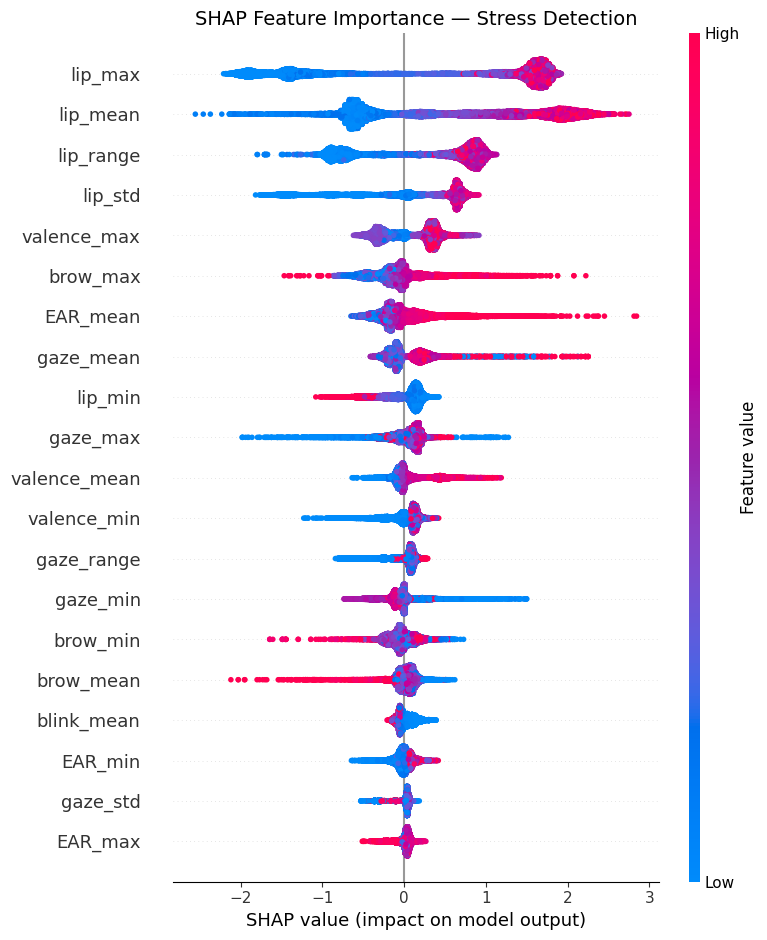

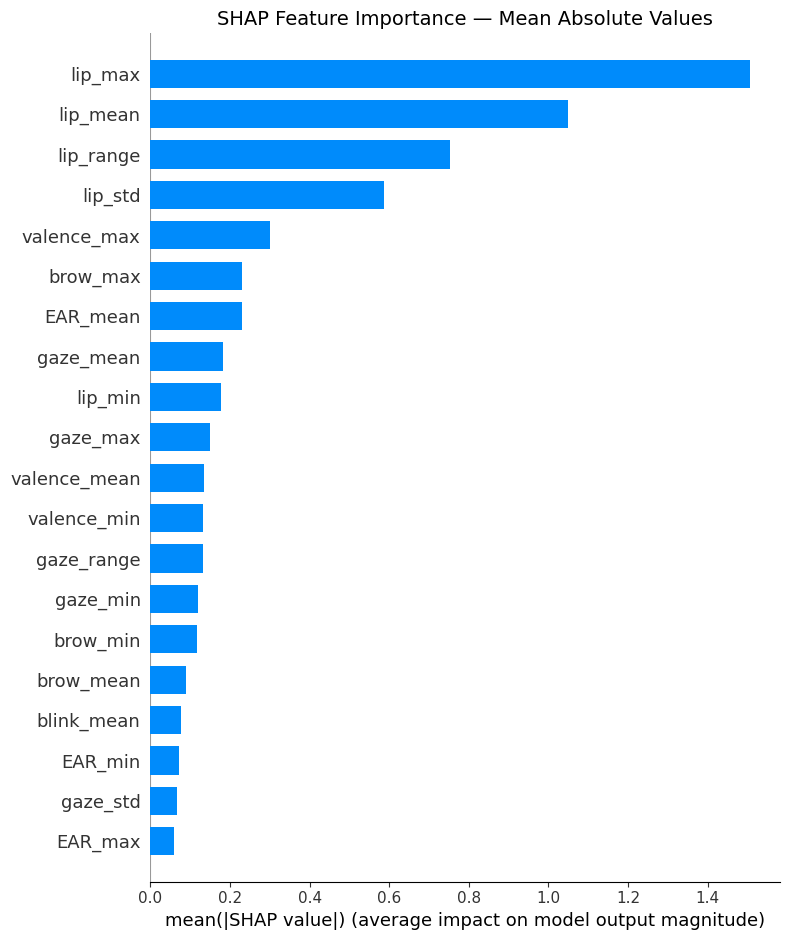

SHAP plots saved!


In [11]:
# ============================================================
# CELL 8 — SHAP Analysis
# ============================================================
print("Running SHAP analysis on XGBoost...")

ALL_FEATURES = GEO_FEATURES + VAL_FEATURES

X = df[ALL_FEATURES].values.astype(float)
y = df['label'].values

# Handle NaN
col_means = np.nanmean(X, axis=0)
for j in range(X.shape[1]):
    X[np.isnan(X[:, j]), j] = col_means[j]

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train XGBoost on full dataset
clf_shap = XGBClassifier(
    n_estimators=100, max_depth=4, learning_rate=0.1,
    eval_metric='logloss', random_state=42, verbosity=0
)
clf_shap.fit(X_scaled, y)

# SHAP
explainer   = shap.TreeExplainer(clf_shap)
shap_values = explainer.shap_values(X_scaled)

print(f"SHAP values computed — shape: {shap_values.shape}")

# Summary plot
plt.figure(figsize=(10, 10))
shap.summary_plot(shap_values, X_scaled,
                  feature_names=ALL_FEATURES, show=False)
plt.title("SHAP Feature Importance — Stress Detection", fontsize=14)
plt.tight_layout()
plt.savefig(SHAP_PATH, dpi=150, bbox_inches='tight')
plt.show()

# Bar plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_scaled,
                  feature_names=ALL_FEATURES,
                  plot_type="bar", show=False)
plt.title("SHAP Feature Importance — Mean Absolute Values", fontsize=14)
plt.tight_layout()
plt.savefig(SHAP_BAR_PATH, dpi=150, bbox_inches='tight')
plt.show()

print(f"SHAP plots saved!")

In [13]:
# ============================================================
# CELL 9 — Complete results summary
# ============================================================
print("="*55)
print("COMPLETE ML PIPELINE RESULTS SUMMARY")
print("="*55)

print("\n1. LATE FUSION RESULTS (T1 vs T2+T3):")
print("-"*55)
print(f"{'Classifier':<20} {'Accuracy':>10} {'F1':>8} {'Precision':>10} {'Recall':>8}")
print("-"*55)
for clf in ['SVM_Linear', 'XGBoost', 'RandomForest']:
    r = df_all_results[df_all_results['classifier']==clf]
    print(f"{clf:<20} {r['accuracy'].mean()*100:>9.2f}% "
          f"{r['f1'].mean():>8.4f} "
          f"{r['precision'].mean():>10.4f} "
          f"{r['recall'].mean():>8.4f}")

print(f"\n{'Baseline':<20} {'64.60%':>10}")

print("\n2. ABLATION STUDY (SVM Linear):")
print("-"*55)
print(f"{'Stream':<28} {'Accuracy':>10} {'F1':>8}")
print("-"*40)
print(f"{'Geometric only':<28} {geo_acc*100:>9.2f}% {geo_f1:>8.4f}")
print(f"{'Valence only':<28} {val_acc*100:>9.2f}% {val_f1:>8.4f}")
print(f"{'Combined (late fusion)':<28} {svm_combined*100:>9.2f}% {svm_combined_f1:>8.4f}")

print("\n3. FUSION WEIGHTS (average across 56 folds):")
print("-"*55)
for clf in ['SVM_Linear', 'XGBoost', 'RandomForest']:
    r = df_all_results[df_all_results['classifier']==clf]
    print(f"{clf:<20} w1={r['w1'].mean():.4f} (geo)  w2={r['w2'].mean():.4f} (val)")

print("\n4. TOP 5 SHAP FEATURES:")
print("-"*55)
feature_importance = np.abs(shap_values).mean(axis=0)
top5_idx = np.argsort(feature_importance)[::-1][:5]
for i, idx in enumerate(top5_idx):
    print(f"  {i+1}. {ALL_FEATURES[idx]:<20} importance: {feature_importance[idx]:.4f}")

print("\n" + "="*55)
print("ML PIPELINE COMPLETE!")
print("="*55)

COMPLETE ML PIPELINE RESULTS SUMMARY

1. LATE FUSION RESULTS (T1 vs T2+T3):
-------------------------------------------------------
Classifier             Accuracy       F1  Precision   Recall
-------------------------------------------------------
SVM_Linear               92.70%   0.9422     0.9601   0.9337
XGBoost                  92.53%   0.9438     0.9451   0.9509
RandomForest             89.63%   0.9257     0.9053   0.9560

Baseline                 64.60%

2. ABLATION STUDY (SVM Linear):
-------------------------------------------------------
Stream                         Accuracy       F1
----------------------------------------
Geometric only                   92.69%   0.9406
Valence only                     72.40%   0.8022
Combined (late fusion)           92.70%   0.9422

3. FUSION WEIGHTS (average across 56 folds):
-------------------------------------------------------
SVM_Linear           w1=0.5617 (geo)  w2=0.4383 (val)
XGBoost              w1=0.5553 (geo)  w2=0.4447 (val)

FEATURE GROUP IMPORTANCE (SHAP)
Rank   Group          Importance
--------------------------------
1      Lip                0.8146
2      Valence            0.1464
3      Gaze               0.1304
4      Brow               0.0995
5      EAR                0.0787
6      Blink              0.0212


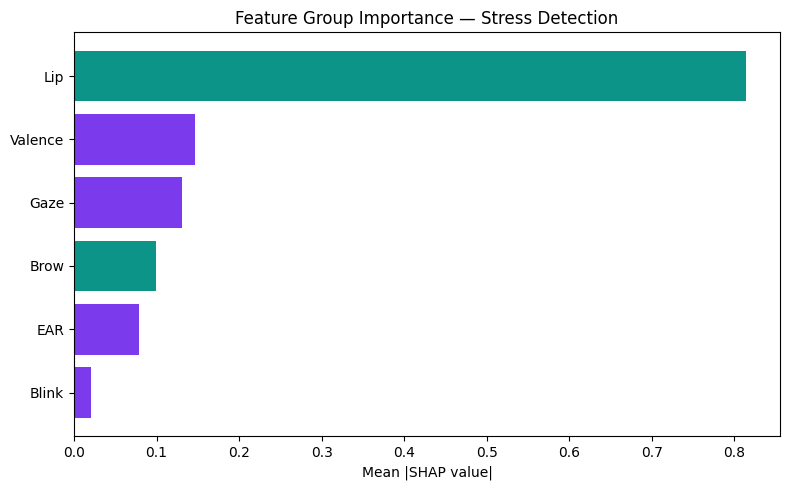

Group importance plot saved!


In [14]:
# Group SHAP values by feature group
feature_groups = {
    'EAR':     [i for i, f in enumerate(ALL_FEATURES) if f.startswith('EAR')],
    'Blink':   [i for i, f in enumerate(ALL_FEATURES) if f.startswith('blink')],
    'Gaze':    [i for i, f in enumerate(ALL_FEATURES) if f.startswith('gaze')],
    'Brow':    [i for i, f in enumerate(ALL_FEATURES) if f.startswith('brow')],
    'Lip':     [i for i, f in enumerate(ALL_FEATURES) if f.startswith('lip')],
    'Valence': [i for i, f in enumerate(ALL_FEATURES) if f.startswith('valence')]
}

# Compute mean absolute SHAP per group
group_importance = {}
for group_name, indices in feature_groups.items():
    group_importance[group_name] = np.abs(shap_values[:, indices]).mean()

# Sort by importance
group_importance = dict(sorted(group_importance.items(), 
                               key=lambda x: x[1], reverse=True))

# Print results
print("="*45)
print("FEATURE GROUP IMPORTANCE (SHAP)")
print("="*45)
print(f"{'Rank':<6} {'Group':<12} {'Importance':>12}")
print("-"*32)
for rank, (group, importance) in enumerate(group_importance.items(), 1):
    print(f"{rank:<6} {group:<12} {importance:>12.4f}")

# Bar plot
plt.figure(figsize=(8, 5))
plt.barh(list(group_importance.keys())[::-1], 
         list(group_importance.values())[::-1],
         color=['#7C3AED', '#7C3AED', '#0D9488', '#7C3AED', '#7C3AED', '#0D9488'])
plt.xlabel("Mean |SHAP value|")
plt.title("Feature Group Importance — Stress Detection")
plt.tight_layout()
plt.savefig(r"C:\Users\hp\StressDetection\ML\shap_groups.png", 
            dpi=150, bbox_inches='tight')
plt.show()
print("Group importance plot saved!")

Running SHAP analysis on XGBoost — T1 vs T3 only (excluding T2 speech)...
Rows: 19824
Label balance: {0: 9912, 1: 9912}


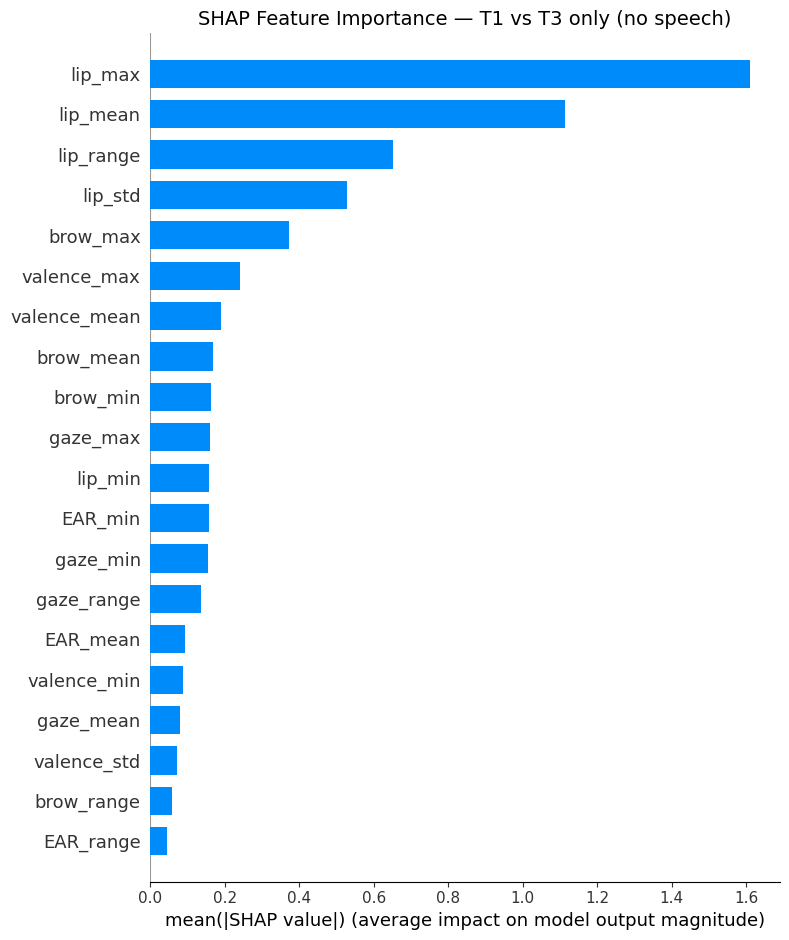

Done!


In [15]:
print("Running SHAP analysis on XGBoost — T1 vs T3 only (excluding T2 speech)...")

# Filter T1 and T3 only
df_t1t3 = df[df['task'].isin(['T1', 'T3'])].copy()
print(f"Rows: {len(df_t1t3)}")
print(f"Label balance: {df_t1t3['label'].value_counts().to_dict()}")

X_t3 = df_t1t3[ALL_FEATURES].values.astype(float)
y_t3 = df_t1t3['label'].values

# Handle NaN
col_means = np.nanmean(X_t3, axis=0)
for j in range(X_t3.shape[1]):
    X_t3[np.isnan(X_t3[:, j]), j] = col_means[j]

# Scale
scaler_t3 = StandardScaler()
X_t3_scaled = scaler_t3.fit_transform(X_t3)

# Train XGBoost
clf_t3 = XGBClassifier(
    n_estimators=100, max_depth=4, learning_rate=0.1,
    eval_metric='logloss', random_state=42, verbosity=0
)
clf_t3.fit(X_t3_scaled, y_t3)

# SHAP
explainer_t3 = shap.TreeExplainer(clf_t3)
shap_values_t3 = explainer_t3.shap_values(X_t3_scaled)

# Bar plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values_t3, X_t3_scaled,
                  feature_names=ALL_FEATURES,
                  plot_type="bar", show=False)
plt.title("SHAP Feature Importance — T1 vs T3 only (no speech)", fontsize=14)
plt.tight_layout()
plt.savefig(r"C:\Users\hp\StressDetection\ML\shap_bar_t1t3.png", dpi=150, bbox_inches='tight')
plt.show()

print("Done!")

In [16]:
import shap
import matplotlib.pyplot as plt

# Show only top 10
shap.summary_plot(shap_values, X_test, 
                  plot_type="bar",
                  feature_names=feature_names,
                  max_display=10,
                  show=False)
plt.title("Top 10 SHAP Feature Importance")
plt.tight_layout()
plt.savefig("shap_top10.png", dpi=300, bbox_inches='tight')

NameError: name 'X_test' is not defined

Saved to shap_top10_paper.png


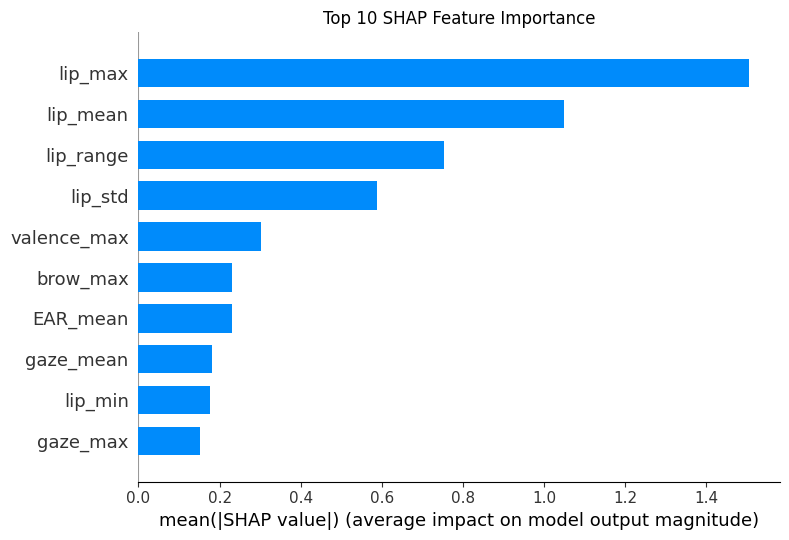

In [17]:
# ============================================================
# Generate Top 10 SHAP bar chart for paper
# ============================================================
import shap
import matplotlib.pyplot as plt

ALL_FEATURES = GEO_FEATURES + VAL_FEATURES

# Train XGBoost on all data
X_all = df[ALL_FEATURES].values.astype(float)
y_all = df['label'].values

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

model_shap = XGBClassifier(n_estimators=100, max_depth=4, 
                            learning_rate=0.1, random_state=42, 
                            verbosity=0, eval_metric='logloss')
model_shap.fit(X_scaled, y_all)

explainer = shap.TreeExplainer(model_shap)
shap_values = explainer.shap_values(X_scaled)

# Top 10 bar chart
plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values, X_scaled,
                  plot_type="bar",
                  feature_names=ALL_FEATURES,
                  max_display=10,
                  show=False)
plt.title("Top 10 SHAP Feature Importance")
plt.tight_layout()
plt.savefig(r"C:\Users\hp\StressDetection\ML\shap_top10_paper.png", 
            dpi=300, bbox_inches='tight')
print("Saved to shap_top10_paper.png")

Saved!


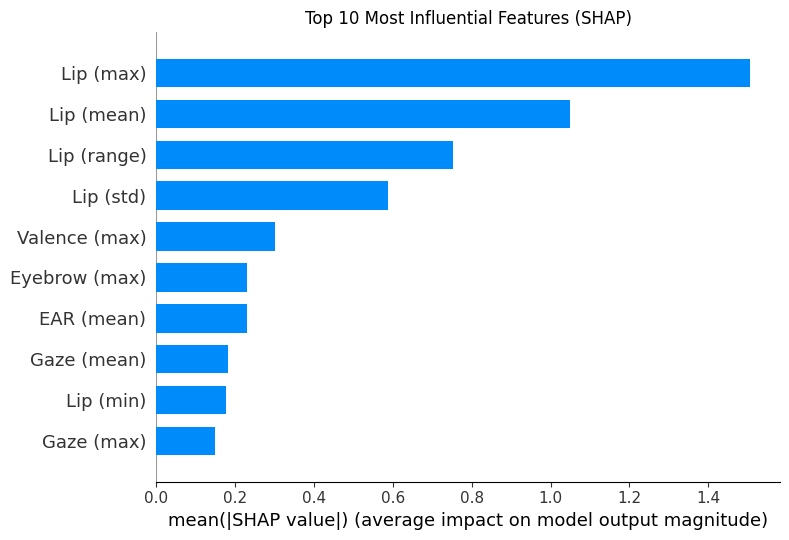

In [18]:
import matplotlib.pyplot as plt
import shap

# Rename features for paper
feature_names_paper = [
    'EAR (mean)', 'EAR (std)', 'EAR (min)', 'EAR (max)', 'EAR (range)',
    'Blink (mean)', 'Blink (std)', 'Blink (min)', 'Blink (max)', 'Blink (range)',
    'Gaze (mean)', 'Gaze (std)', 'Gaze (min)', 'Gaze (max)', 'Gaze (range)',
    'Eyebrow (mean)', 'Eyebrow (std)', 'Eyebrow (min)', 'Eyebrow (max)', 'Eyebrow (range)',
    'Lip (mean)', 'Lip (std)', 'Lip (min)', 'Lip (max)', 'Lip (range)',
    'Valence (mean)', 'Valence (std)', 'Valence (min)', 'Valence (max)'
]

plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values, X_scaled,
                  plot_type="bar",
                  feature_names=feature_names_paper,
                  max_display=10,
                  show=False)
plt.title("Top 10 Most Influential Features (SHAP)")
plt.tight_layout()
plt.savefig(r"C:\Users\hp\StressDetection\ML\shap_top10_paper.png",
            dpi=300, bbox_inches='tight')
print("Saved!")